# Session 7 — Training a Neural Network: Reading the Curves

In Session 6 we wrote the training loop and used it to train a small network on XOR. This session is about the more common situation: you train a model, the result is disappointing, and you have to work out why.

Every plot in this notebook comes from a real training run. Nothing is drawn by hand.

**By the end of the session you should be able to:**

1. look at a training and validation loss plot and say whether the model is too simple, too flexible, or taking steps that are too big;
2. choose a fix that matches the problem;
3. run one quick check that catches bugs the loss curves can hide.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `scikit-learn` and `torch`. The outputs are already saved in the notebook. Re-running everything takes about 30 seconds on a laptop CPU, and the numbers should match the text because every run starts from a fixed seed.

## The data

We use the two half-moons from Session 3, with one change: only **80 training points**. A small training set makes the problems in this session easy to produce, and easy to see.

The 920 remaining points are the validation set. That is far more than you would normally keep aside, but it makes the validation curves smooth enough to read clearly.

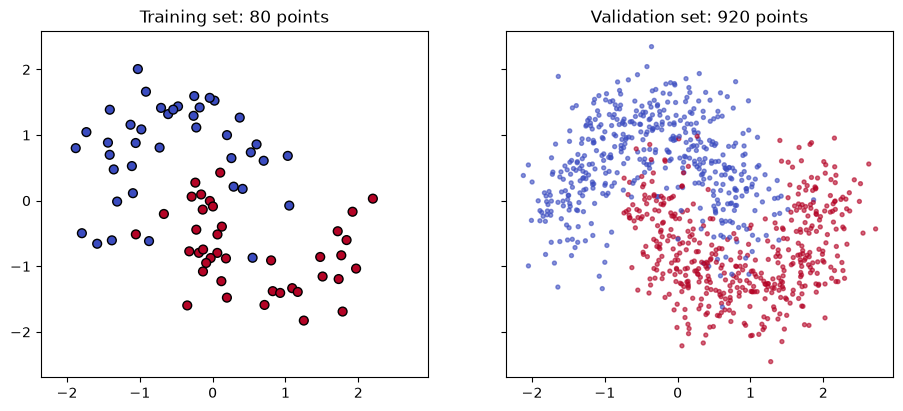

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 0
X, y = make_moons(n_samples=1000, noise=0.25, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X, y, train_size=80, stratify=y, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train, X_val = scaler.transform(X_train), scaler.transform(X_val)
X_train_t, X_val_t = torch.tensor(X_train, dtype=torch.float32), torch.tensor(X_val, dtype=torch.float32)
y_train_t, y_val_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1), torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
axes[0].scatter(*X_train.T, c=y_train, cmap="coolwarm", edgecolor="k", s=40)
axes[0].set_title(f"Training set: {len(X_train)} points")
axes[1].scatter(*X_val.T, c=y_val, cmap="coolwarm", s=8, alpha=0.6)
axes[1].set_title(f"Validation set: {len(X_val)} points")
plt.show()

*Helper code: presenters can skip the next cell on screen.* It defines the functions the experiments use:

- `build_model` creates a network from the settings we will change: hidden layer sizes and dropout.
- `train` is Session 6's loop, with two additions. It goes through the 80 training points in **mini-batches** of 32, taking one step per batch, and after every epoch it records the training and validation loss. Its arguments are the learning rate, the L2 strength and, for early stopping, the patience.
- `evaluate` and `scores` measure loss and accuracy; `plot_curves` and `plot_boundary` draw the two kinds of picture used throughout.

In [2]:
loss_fn = nn.BCELoss()


def build_model(hidden=(64, 64), dropout=0.0, output=None):
    torch.manual_seed(SEED)  # same starting weights every time
    layers, width = [], 2
    for units in hidden:
        layers += [nn.Linear(width, units), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = units
    layers += [nn.Linear(width, 1), output if output is not None else nn.Sigmoid()]
    return nn.Sequential(*layers)


def evaluate(model, X, y):
    model.eval()  # switches dropout off
    with torch.no_grad():
        probabilities = model(X)
    return loss_fn(probabilities, y).item(), ((probabilities >= 0.5).float() == y).float().mean().item()


def train(model, learning_rate=0.01, l2=0.0, epochs=200, patience=None):
    """Session 6's loop with batches of 32. Records training and validation loss after every epoch.
    With patience=N it stops after N epochs without a better validation loss and goes back to the best weights."""
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    order = torch.Generator().manual_seed(SEED)
    history, best_weights = {"loss": [], "val_loss": []}, None
    for epoch in range(epochs):
        model.train()
        for batch in torch.randperm(len(X_train_t), generator=order).split(32):
            loss = loss_fn(model(X_train_t[batch]), y_train_t[batch])
            if l2:
                hidden_layers = [layer for layer in model if isinstance(layer, nn.Linear)][:-1]  # the penalty covers the hidden layers' weights
                loss = loss + l2 * sum((layer.weight ** 2).sum() for layer in hidden_layers)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        history["loss"].append(evaluate(model, X_train_t, y_train_t)[0])  # the loss alone, without the L2 penalty
        history["val_loss"].append(evaluate(model, X_val_t, y_val_t)[0])
        if patience:
            best_epoch = int(np.argmin(history["val_loss"]))
            if best_epoch == epoch:
                best_weights = {k: v.clone() for k, v in model.state_dict().items()}
            elif epoch - best_epoch >= patience:
                model.load_state_dict(best_weights)
                break
    return history


def plot_curves(ax, history, title, ylim=(0, 1.5)):
    ax.plot(history["loss"], label="training loss")
    ax.plot(history["val_loss"], label="validation loss")
    ax.set(title=title, xlabel="epoch", ylabel="loss", ylim=ylim)
    if np.median(history["val_loss"]) > ylim[1]:
        ax.text(0.5, 0.75, "validation loss is above the top\nof the chart for the whole run", transform=ax.transAxes, ha="center", color="C1")
    ax.legend()


def plot_boundary(ax, model, title):
    xx, yy = np.meshgrid(np.linspace(-2.6, 2.6, 250), np.linspace(-2.6, 2.6, 250))
    model.eval()
    with torch.no_grad():
        probs = model(torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)).numpy().reshape(xx.shape)
    ax.contourf(xx, yy, probs, levels=[0, 0.5, 1], colors=["#c9daf0", "#f6cfc4"])
    ax.scatter(*X_train.T, c=y_train, cmap="coolwarm", edgecolor="k", s=30)
    ax.set(title=title, xticks=[], yticks=[])


def scores(model):
    train_loss, _ = evaluate(model, X_train_t, y_train_t)
    val_loss, val_accuracy = evaluate(model, X_val_t, y_val_t)
    return {"train loss": train_loss, "val loss": val_loss, "val accuracy": val_accuracy}

## 1. Three runs, three different problems

Below are three networks trained on the same data for 200 epochs. Each has one thing wrong with it:

- one is **too simple** for the pattern in the data;
- one is **too flexible** for 80 training points;
- one takes **steps that are too big** while learning.

All three plots use the same vertical scale.

> **Pause:** before reading past the plots, decide which run is which and what in the curve gave it away.

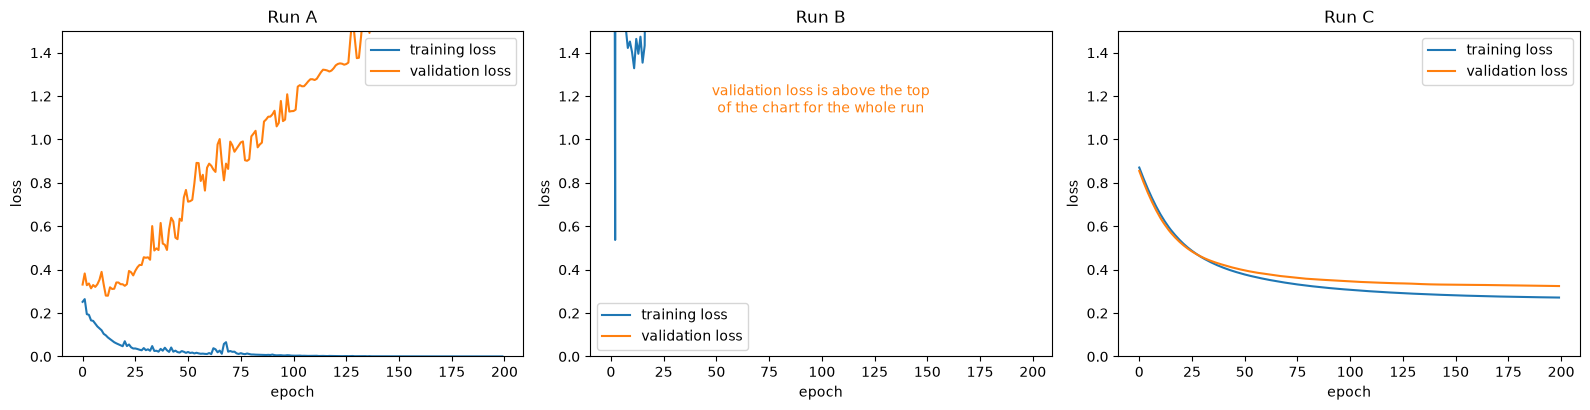

Run A: 66,817 parameters; training loss at epoch 200 0.000; lowest validation loss 0.28 at epoch 13, 1.99 at epoch 200
Run B: training loss in the first ten epochs [7.97, 6.1, 0.54, 12.25, 6.55, 3.99, 2.98, 1.52, 1.42, 1.45]
       epochs 30, 100 and 200: 2.51, 2.50, 2.50 (training); 6.14 (validation) at epoch 200
Run C: losses at epoch 50 0.38 (training), 0.40 (validation); at epoch 200 0.27 and 0.32


In [3]:
runs = {
    "A": dict(hidden=(256, 256)),
    "B": dict(hidden=(64, 64), learning_rate=0.3),
    "C": dict(hidden=()),
}

models, histories = {}, {}
for name, settings in runs.items():
    models[name] = build_model(settings["hidden"])
    histories[name] = train(models[name], learning_rate=settings.get("learning_rate", 0.01))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, name in zip(axes, runs):
    plot_curves(ax, histories[name], f"Run {name}")
plt.tight_layout()
plt.show()

a, b, c = histories["A"], histories["B"], histories["C"]
print(f"Run A: {sum(p.numel() for p in models['A'].parameters()):,} parameters; training loss at epoch 200 {a['loss'][-1]:.3f}; "
      f"lowest validation loss {min(a['val_loss']):.2f} at epoch {np.argmin(a['val_loss']) + 1}, {a['val_loss'][-1]:.2f} at epoch 200")
print(f"Run B: training loss in the first ten epochs {np.round(b['loss'][:10], 2).tolist()}")
print(f"       epochs 30, 100 and 200: {b['loss'][29]:.2f}, {b['loss'][99]:.2f}, {b['loss'][-1]:.2f} (training); {b['val_loss'][-1]:.2f} (validation) at epoch 200")
print(f"Run C: losses at epoch 50 {c['loss'][49]:.2f} (training), {c['val_loss'][49]:.2f} (validation); at epoch 200 {c['loss'][-1]:.2f} and {c['val_loss'][-1]:.2f}")

### What the curves say

**Run C is too simple.** It has no hidden layer, so it is the single unit (logistic regression) from Session 6. Both losses fall and then level off together: 0.38 (training) and 0.40 (validation) at epoch 50, 0.27 and 0.32 at epoch 200. Agreeing curves are normally a good sign. The problem is that the *training* loss stops falling. With only 80 points, a model that can represent the pattern should be able to push its training loss close to zero. If it can't even fit the data it was trained on, it is too limited.

**Run A is too flexible.** It has two hidden layers of 256 neurons: 66,817 parameters to fit 80 points. Its training loss falls to 0.000. Its validation loss is lowest at epoch 13 (0.28), then climbs to 1.99 by epoch 200. After epoch 13, every improvement on the training points makes predictions on new points worse. This is **overfitting**.

**Run B steps too far.** It is an ordinary network with two layers of 64 neurons and a learning rate of 0.3 instead of 0.01. Its training loss starts far off the top of the chart and jumps around: the first ten epochs are 7.97, 6.1, 0.54, 12.25, 6.55, 3.99, 2.98, 1.52, 1.42 and 1.45. Then it gets stuck at 2.50 and never moves again (2.51 at epoch 30, 2.50 at epochs 100 and 200). Its validation loss never even appears on the chart: it ends at 6.14. The huge early steps pushed the weights to extreme values, and the network never recovered.

The fixes are different. Regularisation would make run C worse. A bigger network would make run A worse. Neither would help run B.

### The same three runs as pictures

The shaded regions show what each model predicts at every point of the plane, with the 80 training points drawn on top.

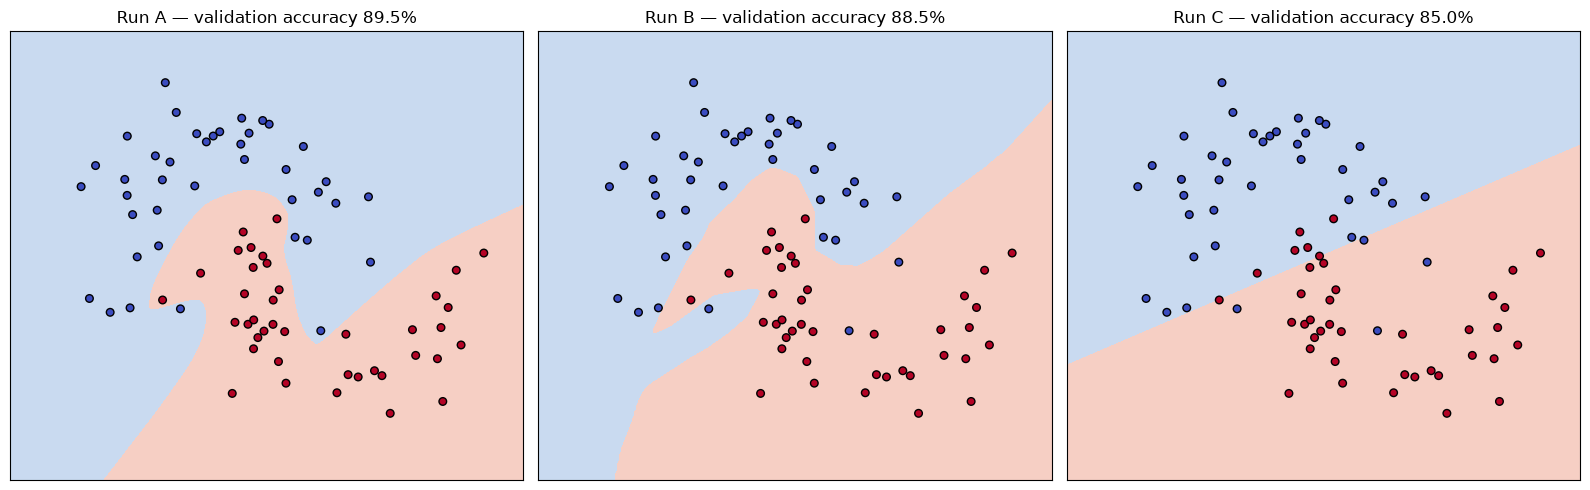

Run A: training accuracy 100.0%; validation predictions below 0.001 or above 0.999 (complete certainty): 89%
Run B: training accuracy 97.5%; validation predictions below 0.001 or above 0.999 (complete certainty): 93%
Run C: training accuracy 87.5%; validation predictions below 0.001 or above 0.999 (complete certainty): 0%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name in zip(axes, runs):
    acc = scores(models[name])["val accuracy"]
    plot_boundary(ax, models[name], f"Run {name} — validation accuracy {acc:.1%}")
plt.tight_layout()
plt.show()
for name in runs:
    models[name].eval()
    with torch.no_grad():
        p = models[name](X_val_t)
    print(f"Run {name}: training accuracy {evaluate(models[name], X_train_t, y_train_t)[1]:.1%}; "
          f"validation predictions below 0.001 or above 0.999 (complete certainty): {((p < 0.001) | (p > 0.999)).float().mean().item():.0%}")

Run C can only draw a straight line, so it cuts through both moons: 87.5% of the training points and 85.0% of the validation points are right. Run A bends its boundary into a hook and a notch to reach individual training points, including ones that sit among the other class. It gets all 80 training points right.

Run B's boundary looks reasonable, and its validation accuracy is 88.5%, higher than run C's. So why is its loss stuck at 2.50? The last line explains it: 93% of its validation predictions are below 0.001 or above 0.999. The network answers with complete certainty, and its training accuracy is 97.5%, so 2 of the 80 training points are wrong *and* certain. Cross-entropy charges a certain wrong answer the maximum (PyTorch caps it at 100 per point), and 2 × 100 / 80 = 2.50. With its outputs pinned at 0 and 1, the gradients that would correct those two points are zero, so training can't move.

Look at run A's validation accuracy too: 89.5%, which is not terrible. Its validation *loss*, however, ended up about seven times its best value. Loss also measures how confident the model is, and run A became very confident (89% of its validation predictions are certain), including about the points it gets wrong. Loss usually shows overfitting before accuracy does, which is why we watch it.

## 2. Learning rate: how big each step is

Each training step works out which direction reduces the loss (that is what backpropagation computes, Session 6) and moves the weights a little that way. The **learning rate** sets the size of that move.

Below, the same 64-neuron network is trained with three learning rates. Only training loss is shown. The vertical axis is logarithmic: each gridline is ten times the one below it. That is the only way to fit all three runs on one chart.

> **Pause:** which line do you expect to be the slowest?

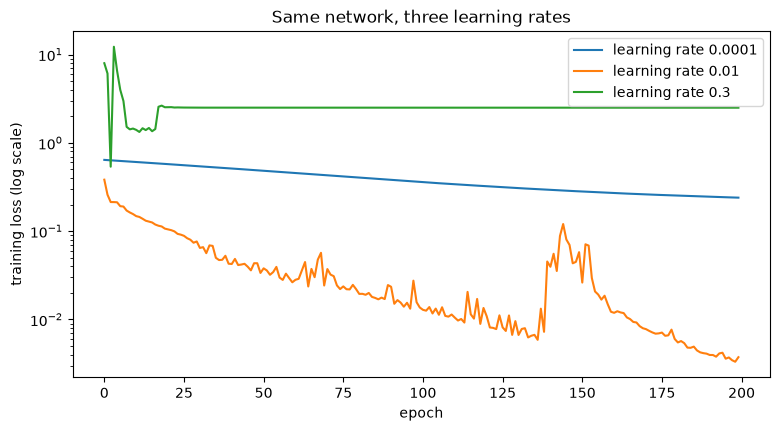

learning rate 0.0001: training loss 0.533 at epoch 34, 0.240 at epoch 200; first epoch below 0.05: never
learning rate 0.01: training loss 0.069 at epoch 34, 0.004 at epoch 200; first epoch below 0.05: 36
learning rate 0.3: training loss 2.503 at epoch 34, 2.500 at epoch 200; first epoch below 0.05: never


In [5]:
learning_rates = [0.0001, 0.01, 0.3]
lr_histories = {0.0001: train(build_model(), learning_rate=0.0001),
                0.01: train(build_model(), learning_rate=0.01),
                0.3: histories["B"]}  # already trained in section 1

fig, ax = plt.subplots(figsize=(9, 4.5))
for lr in learning_rates:
    ax.plot(lr_histories[lr]["loss"], label=f"learning rate {lr}")
ax.set(yscale="log", xlabel="epoch", ylabel="training loss (log scale)", title="Same network, three learning rates")
ax.legend()
plt.show()
for lr in learning_rates:
    h = lr_histories[lr]
    below = next((i + 1 for i, v in enumerate(h["loss"]) if v < 0.05), "never")
    print(f"learning rate {lr}: training loss {h['loss'][33]:.3f} at epoch 34, {h['loss'][-1]:.3f} at epoch 200; first epoch below 0.05: {below}")

- **0.0001** is safe but slow. Its training loss is 0.533 at epoch 34 and still 0.240 at epoch 200, falling slowly, so it would need far more time to get anywhere.
- **0.01** is 0.069 at epoch 34, drops below 0.05 at epoch 36 and reaches 0.004 by epoch 200. Its line is noisy, with a brief spike late in the run: Adam's steps with this learning rate are still large enough to overshoot now and then.
- **0.3** jumps around for its first epochs, then stalls at 2.50 (2.503 at epoch 34, 2.500 at epoch 200). Going too fast doesn't just waste the first few epochs; it can leave the network stuck in a worse place than the slow run.

Adam, the optimiser used here, adjusts the step size for each weight separately. You still have to give it a sensible starting learning rate: 0.001 or 0.01 is a common first guess.

The 0.01 run fits the 80 training points almost perfectly. Its validation loss (not shown) then rises, the same way as run A's. A good learning rate gets you to the overfitting problem faster; it doesn't solve it. That's the next section.

## 3. Fixing overfitting, one change at a time

We start from run A and try three standard fixes. Each run changes **exactly one thing** from run A, so if the result changes, we know why.

- **Early stopping** watches validation loss and stops once it has not improved for 20 epochs, then goes back to the best weights it saw.
- **Dropout** randomly switches off half of the hidden neurons at every training step, so the network cannot rely on any single one. It is switched off when the model makes predictions.
- **L2 regularisation** adds a penalty for large weights to the loss, which pushes the network towards smoother boundaries.

The last run uses far too much L2. It shows what happens when the cure is overdone.

> **Pause:** which of these do you expect to help the most?

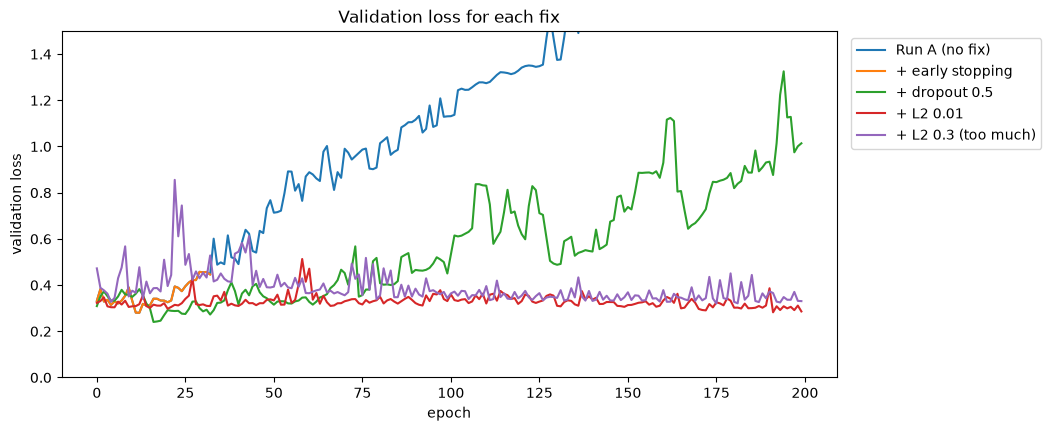

early stopping: stopped after 33 epochs and kept the weights from epoch 13
dropout: lowest validation loss 0.24 at epoch 17, 1.01 at epoch 200


,train loss,val loss,val accuracy,epochs trained
Run A (no fix),0.000,1.992,0.895,200
+ early stopping,0.088,0.280,0.910,33
+ dropout 0.5,0.026,1.014,0.925,200
+ L2 0.01,0.160,0.286,0.886,200
+ L2 0.3 (too much),0.300,0.331,0.852,200


In [6]:
fix_settings = {
    "+ early stopping": dict(),
    "+ dropout 0.5": dict(dropout=0.5),
    "+ L2 0.01": dict(l2=0.01),
    "+ L2 0.3 (too much)": dict(l2=0.3),
}

fix_models = {"Run A (no fix)": models["A"]}
fix_histories = {"Run A (no fix)": histories["A"]}
for name, settings in fix_settings.items():
    fix_models[name] = build_model((256, 256), dropout=settings.get("dropout", 0.0))
    fix_histories[name] = train(fix_models[name], l2=settings.get("l2", 0.0), patience=20 if name == "+ early stopping" else None)

fig, ax = plt.subplots(figsize=(10, 4.5))
for name, history in fix_histories.items():
    ax.plot(history["val_loss"], label=name)
ax.set(ylim=(0, 1.5), xlabel="epoch", ylabel="validation loss", title="Validation loss for each fix")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

e, d = fix_histories["+ early stopping"], fix_histories["+ dropout 0.5"]
print(f"early stopping: stopped after {len(e['val_loss'])} epochs and kept the weights from epoch {np.argmin(e['val_loss']) + 1}")
print(f"dropout: lowest validation loss {min(d['val_loss']):.2f} at epoch {np.argmin(d['val_loss']) + 1}, {d['val_loss'][-1]:.2f} at epoch 200")
summary = pd.DataFrame({name: scores(model) for name, model in fix_models.items()}).T
summary["epochs trained"] = [len(h["loss"]) for h in fix_histories.values()]
summary.round(3)

The curves and the table score every model on its predictions alone; the L2 penalty is added only to the loss used for training.

- **Early stopping** stopped after 33 epochs and kept the weights from epoch 13. Its validation loss is 0.280, against 1.992 for run A, the lowest of all the runs. It is the cheapest fix and the one to turn on first.
- **Dropout** is the interesting one. At epoch 17 it reached the lowest validation loss of any curve on the chart (0.24), then drifted back up, with large swings, to 1.01 at epoch 200. On its own it delays overfitting rather than preventing it. Its validation accuracy (0.925) is the best in the table even though its loss is poor, the same disagreement between loss and accuracy as run A. Combined with early stopping, it would have kept the weights from its best epoch. Once you know that each fix helps on its own, combining them is normal.
- **L2 at 0.01** keeps the validation loss flat for the whole run and ends at 0.286, almost as low as early stopping, with accuracy 0.886.
- **L2 at 0.3** penalised the weights so hard that the network could no longer bend its boundary. Its training loss is back up to 0.300 and its validation loss is 0.331: it now behaves like run C (0.27 and 0.32), too simple.

Which fix works best depends on the problem. The method doesn't: change one thing, compare on validation data, keep what helps.

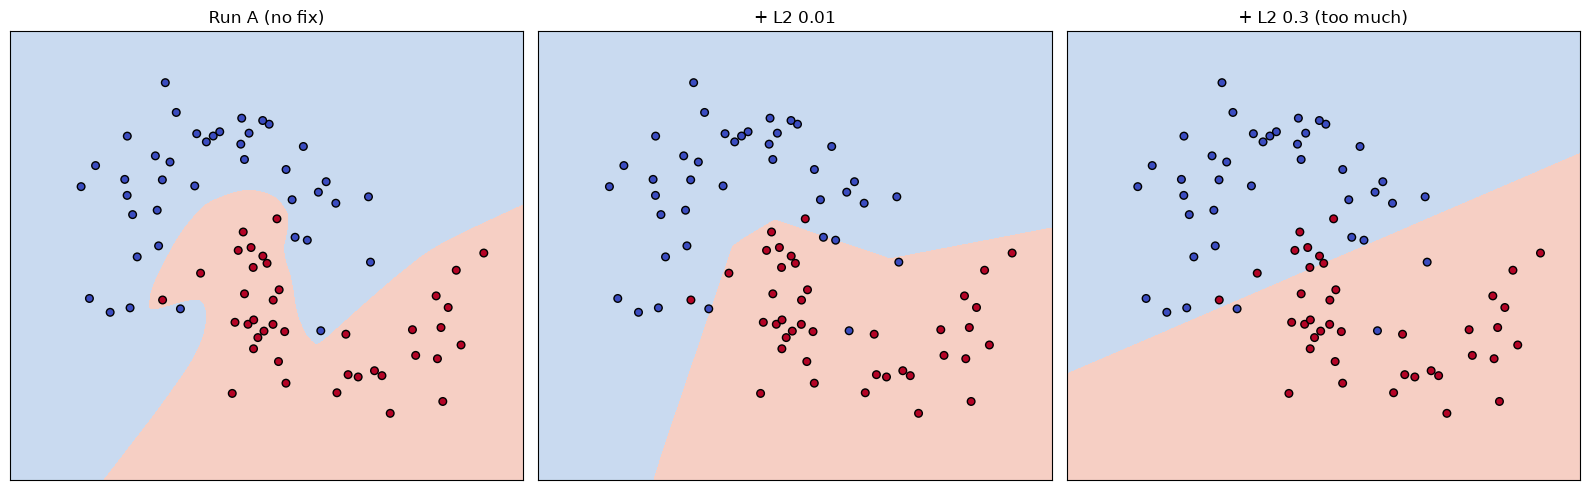

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name in zip(axes, ["Run A (no fix)", "+ L2 0.01", "+ L2 0.3 (too much)"]):
    plot_boundary(ax, fix_models[name], name)
plt.tight_layout()
plt.show()

From left to right: too flexible, about right, too simple. The middle boundary follows the two moons in a few straight pieces and ignores single stray points; the right one is a straight line, like run C's.

## 4. When the curves look fine but the model is broken

Some bugs give perfectly healthy-looking loss curves. Here is a quick check that catches many of them.

**Train on a tiny subset, such as 10 examples, and check that the model gets every one right.** A network with thousands of weights should memorise 10 points within seconds. If it can't, the problem is in the code, not the data.

Below are two models that differ in their last layer. The second has a bug that appears in real projects. Each is trained on the first 10 training points with the loop from Session 6.

In [8]:
X_tiny, y_tiny = X_train_t[:10], y_train_t[:10]

for label, output in [("sigmoid output (correct)", nn.Sigmoid()), ("softmax output (bug)", nn.Softmax(dim=0))]:
    model = build_model(output=output)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    losses = []
    for epoch in range(100):
        loss = loss_fn(model(X_tiny), y_tiny)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    with torch.no_grad():
        predictions = model(X_tiny).ravel()
    accuracy = ((predictions >= 0.5).float() == y_tiny.ravel()).float().mean().item()
    print(f"{label}:  loss {losses[0]:.3f} at epoch 1, {losses[19]:.3f} at epoch 20, {losses[-1]:.3f} at epoch 100   accuracy {accuracy:.0%}")
    print("    predicted probabilities:", predictions.numpy().round(2))

print("\ntrue labels:               ", y_tiny.ravel().int().numpy())

sigmoid output (correct):  loss 0.658 at epoch 1, 0.183 at epoch 20, 0.000 at epoch 100   accuracy 100%
    predicted probabilities: [1. 1. 0. 0. 1. 1. 0. 0. 0. 1.]
softmax output (bug):  loss 1.166 at epoch 1, 0.855 at epoch 20, 0.805 at epoch 100   accuracy 50%
    predicted probabilities: [0.2  0.2  0.   0.   0.2  0.21 0.   0.   0.   0.2 ]

true labels:                [1 1 0 0 1 1 0 0 0 1]


Both losses fall: the first from 0.658 to 0.000, the second from 1.166 to 0.805. Only the first model gets the 10 points right. The second scores 50%: every prediction is below 0.5, so it says "0" for every point, and half the labels are 0.

**What went wrong:** softmax turns a list of scores into probabilities that add up to 1. It is meant for choosing between several classes, across the outputs of one example. `nn.Softmax(dim=0)` applies it across the *examples in the batch* instead, so the ten predictions are forced to add up to 1. The model did learn something: the five points labelled 1 get about 0.2 each and the others get 0. But no prediction can reach 0.5, so the answers are useless, while the loss keeps falling. For a single yes/no output, use `sigmoid`.

The lesson: look at a metric you understand, such as accuracy or a few actual predictions, not only the loss. A loss that falls says the optimiser is working, not that the model is right.

## 5. A debugging order

When a network disappoints, work through this list in order. The early steps are quick, and they often find the problem before you start adjusting the model.

1. **Check the data and labels.** Look at a few rows. Are inputs and labels lined up? Are train and validation separate?
2. **Run the tiny-subset check** from section 4. If the model can't memorise 10 points, fix the code first.
3. **Plot training and validation loss** and match the shape to section 1.
4. **If training loss jumps around or won't fall:** lower the learning rate (section 2).
5. **If training loss stays high and level:** the model is too simple. Add capacity or better features.
6. **If validation loss rises while training loss falls:** the model is overfitting. Use early stopping first, then try L2 or dropout, one at a time (section 3).
7. **Look at the examples it gets wrong.** As in Session 0, the errors themselves often explain what the numbers can't.

---

# Going deeper

*The rest of this notebook is for reading after the session. It gives the maths behind the ideas above, plus a few techniques we didn't have time to demonstrate.*

## Batches, epochs and updates

With $n$ training examples and batch size $B$, one **epoch** (one pass through the training set) contains $\lceil n/B \rceil$ **updates**. Our runs used $n=80$ and $B=32$, so each epoch made 3 updates.

Each update estimates the gradient from one batch:

$$
\nabla_\theta L_B(\theta)=\frac{1}{B}\sum_{i\in \text{batch}}\nabla_\theta \ell_i(\theta).
$$

Small batches give noisier estimates and use less memory. Large batches give smoother estimates but often need a different learning rate.

## Gradient descent and the learning rate

Plain gradient descent updates the parameters $\theta$ with

$$
\theta_{t+1}=\theta_t-\eta\,\nabla_\theta L(\theta_t),
$$

where $\eta$ is the learning rate. The gradient gives the direction; $\eta$ gives the distance. A **learning-rate schedule** lowers $\eta$ during training, so early steps cover ground quickly and later steps fine-tune.

## Momentum and Adam

Momentum keeps a running average of recent gradients $g_t$ and moves along that average:

$$
v_t=\beta v_{t-1}+(1-\beta)g_t,\qquad \theta_{t+1}=\theta_t-\eta v_t.
$$

This builds speed in directions that stay consistent and damps zig-zagging.

Adam keeps running averages of both the gradient and its square:

$$
m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2,
$$

and divides each weight's step by $\sqrt{v_t}$. Weights with consistently large gradients take smaller steps, and the reverse. This is why Adam usually works with little tuning, though, as section 2 showed, not with any learning rate.

## L1 and L2 regularisation

L2 adds the sum of squared weights to the loss:

$$
L_{\text{total}}=L_{\text{data}}+\lambda\sum_j w_j^2 .
$$

L1 uses absolute values instead, $\lambda\sum_j |w_j|$, which tends to push many weights to exactly zero. In both cases $\lambda$ sets the strength: it was 0.01 and 0.3 in section 3.

## Dropout

During training, each hidden activation $h_j$ is kept with probability $1-p$ and set to zero otherwise:

$$
\tilde h_j = m_j h_j,\qquad m_j\sim\text{Bernoulli}(1-p).
$$

PyTorch's `nn.Dropout` scales the surviving activations by $1/(1-p)$ during training, so nothing needs changing at prediction time, when dropout is turned off by `model.eval()`. Forgetting `model.eval()` before measuring a model is a common bug: dropout stays on and the scores come out worse and noisy.

## Batch normalisation

Batch normalisation standardises each activation using the mean $\mu_B$ and variance $\sigma_B^2$ of the current batch, then learns a scale $\gamma$ and shift $\beta$:

$$
\hat x=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\varepsilon}},\qquad y=\gamma\hat x+\beta .
$$

In practice it makes training more stable and tolerates larger learning rates. At prediction time it uses running averages collected during training instead of batch statistics, which is why a model behaves differently in training and inference mode.

## Initialisation

If every weight started with the same value, every neuron in a layer would receive the same gradient and they would stay identical. Random initialisation breaks this symmetry. The scale of the random values matters too: too large and signals grow layer after layer; too small and they fade. Glorot (Xavier) and He initialisation pick the variance from the number of inputs to the layer, roughly $1/n_{\text{in}}$ or $2/n_{\text{in}}$. PyTorch's `nn.Linear` draws its starting weights uniformly between $\pm 1/\sqrt{n_{\text{in}}}$, a variance of $1/(3n_{\text{in}})$.